# UTS Web Mining: Klasifikasi Berita (Sport vs Finance)
**Metode:** Word Embedding (Skip-gram) & Gaussian Naive Bayes

Notebook ini dirancang secara ringkas untuk melakukan:
1. Pra-pemrosesan teks (Pembersihan & Sastrawi Stopwords).
2. Ekstraksi fitur menggunakan rata-rata vektor (Mean Pooling) dari Word2Vec Skip-gram.
3. Klasifikasi menggunakan Gaussian Naive Bayes dan Evaluasi Model.


In [1]:
import pandas as pd
import numpy as np
import re
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore') # Menyembunyikan peringatan yang tidak perlu

## 1. Muat Dataset

In [2]:
# Load dataset
df = pd.read_csv("dataset_berita_detik.csv")

print(f"Total data: {df.shape[0]} baris | Distribusi Kelas: \n{df['label'].value_counts()}")
display(df.head(3))

Total data: 200 baris | Distribusi Kelas: 
label
Sport      100
Finance    100
Name: count, dtype: int64


,ID,Isi berita,label
0,1,Persatuan Bulutangkis Indonesia (PBSI) baru sa...,Sport
1,2,"Tunggal putra Indonesia, Jonatan Christie, men...",Sport
2,3,Sabar Karyaman Gutama/Moh Reza Pahlevi Isfahan...,Sport


## 2. Preprocessing Teks Berita
Membersihkan tanda baca, mengubah ke huruf kecil, melakukan tokenisasi, dan menghapus *stopwords*  menggunakan Sastrawi.

In [3]:
# Load stopwords Sastrawi sebagai Set (agar pencarian lebih cepat)
stopwords_id = set(StopWordRemoverFactory().get_stop_words())

def preprocess_text(text):
    # Bersihkan simbol & angka, ubah ke lowercase
    clean_text = re.sub(r'[^a-zA-Z\s]', ' ', str(text)).lower()
    # Tokenisasi dan hapus stopword serta huruf tunggal
    return [w for w in clean_text.split() if w not in stopwords_id and len(w) > 1]

# Terapkan ke dataset
df['tokens'] = df['Isi berita'].apply(preprocess_text)
display(df[['Isi berita', 'tokens']].head(3))

,Isi berita,tokens
0,Persatuan Bulutangkis Indonesia (PBSI) baru sa...,"[persatuan, bulutangkis, indonesia, pbsi, baru..."
1,"Tunggal putra Indonesia, Jonatan Christie, men...","[tunggal, putra, indonesia, jonatan, christie,..."
2,Sabar Karyaman Gutama/Moh Reza Pahlevi Isfahan...,"[sabar, karyaman, gutama, moh, reza, pahlevi, ..."


## 3. Split Data (Train-Test)
Membagi data menjadi 80% untuk training dan 20% untuk Testing.

In [4]:
X = df['tokens']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Jumlah Data Latih: {len(X_train)} | Jumlah Data Uji: {len(X_test)}")

Jumlah Data Latih: 160 | Jumlah Data Uji: 40


## 4. Word Embedding (Skip-gram) & Mean Pooling
Melatih model Word2Vec (Skip-gram) untuk mengubah kata menjadi vektor 100 dimensi. Kemudian, merata-ratakan vektor kata di setiap artikel (Mean Pooling) untuk mewakili satu dokumen utuh.

In [ ]:
# Latih model Skip-gram pada seluruh token data
w2v_model = Word2Vec(sentences=X, 
            vector_size=100, 
            window=5, 
            min_count=2, 
            sg=1, 
            seed=42, 
            workers=1)

# Fungsi untuk menghitung rata-rata vektor (Mean Pooling) per dokumen
def get_mean_vector(tokens, model, dim=100):
    vecs = [model.wv[w] for w in tokens if w in model.wv]
    return np.mean(vecs, axis=0) if len(vecs) > 0 else np.zeros(dim)

# Transformasi data train dan test menjadi matriks angka
X_train_vec = np.array([get_mean_vector(t, w2v_model) for t in X_train])
X_test_vec  = np.array([get_mean_vector(t, w2v_model) for t in X_test])

print(f"Dimensi Matriks Fitur: {X_train_vec.shape}")

Dimensi Matriks Fitur: (160, 100)


### 4.1. Eksplorasi Vektor Kata
Sebelum masuk ke tahap klasifikasi, kita periksa apakah model Skip-gram berhasil menangkap makna kata. Kita akan melihat bentuk matriks angkanya (10 dimensi pertama) dan mencari kata apa saja yang memiliki kedekatan makna (Cosine Similarity) dengan kata "indonesia".

In [10]:
# Tampilkan contoh matriks vektor untuk beberapa kata
sample_words = ['indonesia', 'pertandingan', 'ekonomi', 'saham', 'gol', 'rupiah', 'pemain', 'bank', 'juara']
valid_words = [w for w in sample_words if w in w2v_model.wv]

if valid_words:
    # Buat DataFrame untuk visualisasi (hanya mengambil 10 kolom/dimensi pertama)
    df_vec = pd.DataFrame([w2v_model.wv[w] for w in valid_words], index=valid_words)
    df_vec.columns = [f'dim_{i+1}' for i in range(df_vec.shape[1])]
    
    print("=== CONTOH VEKTOR KATA (10 Dimensi Pertama) ===")
    display(df_vec.iloc[:, :10])

# Cek kata dengan makna terdekat
target_word = 'indonesia'
if target_word in w2v_model.wv:
    print(f"\n=== 10 KATA PALING MIRIP DENGAN '{target_word}' ===")
    for word, sim in w2v_model.wv.most_similar(target_word, topn=10):
        print(f" {word:<20} \t→ similarity = {sim:.4f}")
else:
    print(f"Kata '{target_word}' tidak ditemukan dalam kosakata model.")

=== CONTOH VEKTOR KATA (10 Dimensi Pertama) ===


,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8,dim_9,dim_10
indonesia,0.126889,0.091627,0.150484,-0.264689,-0.120875,-0.003526,0.178967,0.224532,-0.203340,-0.255507
pertandingan,0.176157,-0.148634,0.230548,-0.158306,0.112607,-0.112144,0.183606,0.103055,-0.107172,-0.123587
ekonomi,0.207581,-0.213164,0.163469,-0.180556,0.008550,-0.069603,0.159755,0.114494,-0.031729,-0.193959
saham,0.473893,-0.616208,-0.039129,0.044021,-0.090591,0.132596,0.258287,-0.216861,0.210747,-0.413355
rupiah,0.237077,-0.264940,0.149868,-0.120041,0.011706,-0.024939,0.171084,0.028608,0.012894,-0.214697
pemain,0.183721,-0.132140,0.221203,-0.179580,0.033378,-0.126465,0.117571,0.146095,-0.120199,-0.269832
bank,0.132217,0.216630,-0.233811,-0.456505,-0.293807,0.033658,0.255768,0.310380,-0.254294,-0.061152
juara,0.159248,-0.145460,0.200484,-0.114206,0.074419,-0.081202,0.176478,0.133998,-0.129438,-0.193995



=== 10 KATA PALING MIRIP DENGAN 'indonesia' ===
 simpanan             	→ similarity = 0.9373
 lembaga              	→ similarity = 0.9322
 penjamin             	→ similarity = 0.9318
 sesuai               	→ similarity = 0.9161
 satu                 	→ similarity = 0.9138
 merupakan            	→ similarity = 0.9130
 timur                	→ similarity = 0.9114
 lps                  	→ similarity = 0.9091
 tanggal              	→ similarity = 0.9078
 status               	→ similarity = 0.9059


## 5. Klasifikasi Gaussian Naive Bayes & Evaluasi
Melatih model klasifikasi pada matriks vektor dokumen dan menguji akurasinya.

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Finance       0.95      1.00      0.98        20
       Sport       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40



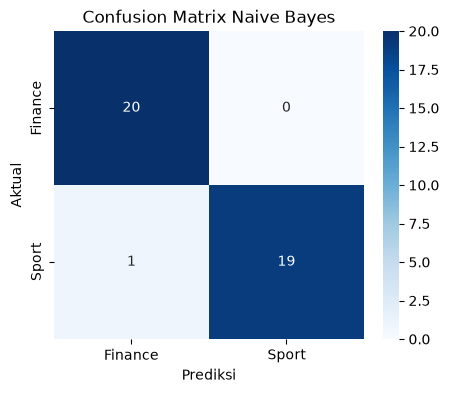

In [7]:
# Inisialisasi dan Latih Model Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train_vec, y_train)

# Prediksi data uji
y_pred = nb_model.predict(X_test_vec)

# Tampilkan Laporan Evaluasi
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=nb_model.classes_)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=nb_model.classes_, yticklabels=nb_model.classes_)
plt.title('Confusion Matrix Naive Bayes')
plt.xlabel('Prediksi'); plt.ylabel('Aktual')
plt.show()

## 6. Visualisasi Sebaran Berita (PCA)
Merampingkan 100 dimensi vektor dokumen menjadi 2 dimensi agar bisa divisualisasikan dalam (Scatter Plot).

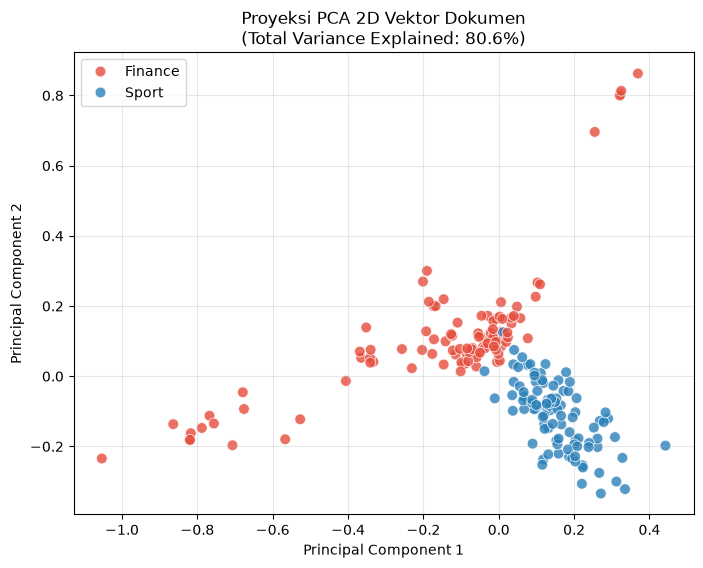

In [8]:
# PCA transformasi (menggabungkan train & test untuk visualisasi)
X_all_vec = np.vstack([X_train_vec, X_test_vec])
y_all = np.concatenate([y_train, y_test])

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_all_vec)

# Plot PCA
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_all, palette=['#e74c3c', '#2980b9'], s=60, alpha=0.8)
plt.title(f'Proyeksi PCA 2D Vektor Dokumen\n(Total Variance Explained: {sum(pca.explained_variance_ratio_)*100:.1f}%)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, alpha=0.3)
plt.show()

## 7. Simpan Model (Export)
Menyimpan vektor kata Skip-gram dan model Naive Bayes agar dapat langsung digunakan pada aplikasi web Streamlit.

In [9]:
import os

# Buat folder Output jika belum ada
os.makedirs("Output/models", exist_ok=True)

# Simpan kamus vektor kata & size-nya
word_vectors = {word: w2v_model.wv[word] for word in w2v_model.wv.index_to_key}
joblib.dump({"vectors": word_vectors, "vector_size": 100}, "Output/models/skipgram_vectors.pkl")

# Simpan model klasifikasi dan label kelas
joblib.dump(nb_model, "Output/models/naive_bayes_model.pkl")
joblib.dump(nb_model.classes_, "Output/models/classes.pkl")

print("File model berhasil disimpan di folder 'Output/models/'!")

File model berhasil disimpan di folder 'Output/models/'!


## 11. Link Aplikasi Deteksi Berita

**https://utsppw-9znx4fmyon32pd8zyhezqd.streamlit.app/**